# Breast Cancer Diagnosis with Random Forest
Predicting whether a tumor is **malignant (M)** or **benign (B)** from cell-nucleus measurements (Breast Cancer Wisconsin dataset, 569 samples).

## 1: Import Libraries
Load pandas for data handling, matplotlib for plots, and scikit-learn for modeling and evaluation.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split , cross_val_score
from sklearn.metrics import accuracy_score , classification_report , ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier

## 2: Load the Dataset
Read `Cancer_Data.csv` into a DataFrame and preview the first 5 rows.

In [2]:
df = pd.read_csv("Cancer_Data.csv")
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


## 3: Dataset Info
Check the number of rows, columns, and data types of each feature.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

## 4: Check for Missing Values
Count null values in every column. Only the empty `Unnamed: 32` column has missing data.

In [4]:
df.isna().sum()

id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_worst      0
Unnamed:

## 5: Drop Unnecessary Columns
Remove `id` (just an identifier) and `Unnamed: 32` (completely empty). Neither helps prediction.

In [ ]:
df = df.drop(["Unnamed: 32","id"],axis=1)

## 6: Define Features (x) and Target (y)
- `x`: all measurement features
- `y`: the `diagnosis` column (M = malignant, B = benign)

In [7]:
x = df.drop("diagnosis",axis=1)
y = df["diagnosis"]

## 7: Train/Test Split
80% training, 20% testing. `stratify=y` keeps the same B/M ratio in both sets, and `random_state=42` makes result reproducible.

In [10]:
x_train , x_test , y_train , y_test = train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

## 8: Build, Train, and Predict with Random Forest
- 200 trees (`n_estimators=200`)
- `class_weight="balanced"` gives more weight to the smaller class (M)

In [ ]:
model_rf = RandomForestClassifier(random_state=42,
                                  n_estimators=200,  
                                  class_weight="balanced",
                                  )
model_rf.fit(x_train,y_train)
y_pred = model_rf.predict(x_test)

## 9: Evalution on the Test set
Accuracy plus the classification report (precision,recall,F1-score for each class).

In [19]:
print(accuracy_score(y_test,y_pred))
print(classification_report(y_test,y_pred))

0.9649122807017544
              precision    recall  f1-score   support

           B       0.95      1.00      0.97        72
           M       1.00      0.90      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.95      0.96       114
weighted avg       0.97      0.96      0.96       114



## 10: Cross-Validation
5-fold cross-validation to check that the result is stable and not dependent on one lucky split.

In [20]:
scores = cross_val_score(model_rf,x,y,cv=5,scoring='accuracy')
print(scores)
print(scores.mean())

[0.92105263 0.93859649 0.97368421 0.96491228 0.96460177]
0.9525694767893185


## 11: Confusion Matrix
Shows exactly where the model makes mistakes. The most important error here is a malignant tumor predicted as benign (false negative).

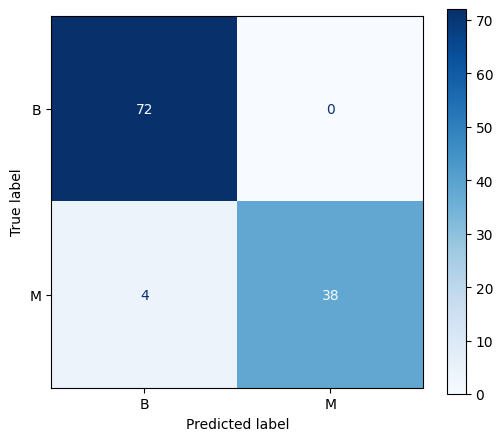

In [34]:
fig , ax = plt.subplots(figsize=(6,5))
ConfusionMatrixDisplay.from_predictions(y_test,y_pred,cmap="Blues",ax=ax)
plt.savefig("confusion_matrix.png",dpi=300,bbox_inches='tight')
plt.show()

## 12: Feature Importance
The 10 features that contributed most to the model's decisions.

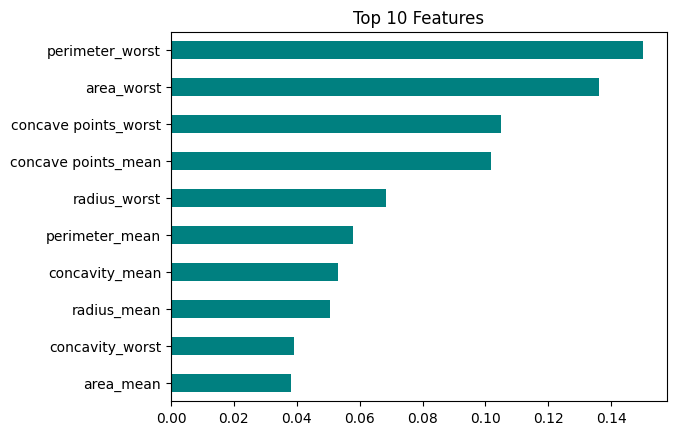

In [ ]:
importances = pd.Series(model_rf.feature_importances_,index=x.columns)
importances.sort_values().tail(10).plot(kind='barh',color='teal')
plt.title("Top 10 Features")
plt.show()

## 13: Conclusion
- Test accuracy: ~96.5%
- Cross-validation accuracy: ~95.3%
- Benign recall: 1.00, malignant recall: 0.90 (4 malignant cases missed out of 42)
- Most important features: `perimeter_worst` , `area_worst` , `concave points_worst`
- Next step: improve malignant recall (threshold tuning, model comparison)